# Promptable segmentation with SAM 3 and SAM 2.1: clicks, boxes and ambiguity

A robot that has to pick up "that object" needs a pixel-accurate mask of it, not only a
bounding box. **Promptable segmentation** models turn a cheap hint (a click, a box, a
rough mask) into such a mask for *any* object, without class labels or task-specific
training. This notebook compares the two current open families of the Segment Anything
line on real COCO images:

* **SAM 3** (`facebook/sam3`, Meta, Nov 2025) - here its *tracker* head
  (`Sam3TrackerModel`), the SAM 2-style interactive segmenter that sits on SAM 3's
  Perception Encoder backbone;
* **SAM 2.1** (`facebook/sam2.1-hiera-{tiny,small,base-plus}`) - the previous generation,
  in three sizes.

**What you will learn**

1. How SAM-style models split the work into a heavy *image encoder* (run once per image)
   and a light *prompt encoder + mask decoder* (run once per click).
2. Why a single click is ambiguous and how **multimask output** with a predicted IoU
   handles it.
3. How box prompts and positive/negative refinement clicks work, and how interactive
   segmentation is evaluated (mIoU after *k* clicks, NoC@90).
4. How to measure latency and peak VRAM correctly on a GPU.

**Prerequisites**: `make data-05_segmentation` (coco8-seg / coco128-seg, SAM 3 and SAM 2.1
checkpoints; SAM 3 is gated - accept its licence on Hugging Face first). The
`## Results` section loads the 128-image benchmark written by
`projects/05_segmentation/scripts/benchmark_coco.py --task prompts` (about 10 minutes on
the GPU), because evaluating 861 instances x 4 models x 7 prompts live would exceed this
notebook's time budget. Hardware for every number below: RTX 5060 Laptop GPU (8 GB).

## Setup

Imports, seeding and device selection (`cvlab.device.setup` prints the software and GPU
versions so the outputs below are traceable), repository-relative paths and the shared
plotting style.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# segkit (projects/05_segmentation/scripts/segkit.py) holds the data loaders, metrics and
# model adapters shared by all notebooks of this project, the benchmark script and the solutions.
# Photo grids are displayed with sk.show_jpeg (JPEG is ~5-10x smaller than PNG for photos);
# charts stay PNG via plt.show().
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import track_vram
from cvlab.io import project_dir, repo_root

PROJECT = "05_segmentation"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import segkit as sk  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
warnings.filterwarnings("ignore")  # silence library warnings in the rendered notebook
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
RESULTS = sk.results_dir()
print("results dir:", RESULTS.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


results dir: projects/05_segmentation/results


## Data: COCO instance masks from YOLO polygons

Ultralytics' **coco8-seg** contains 8 COCO train2017 images whose instance outlines are
stored as normalised polygons `class x1 y1 x2 y2 ...`. `segkit.polygons_to_masks`
rasterises each polygon with `cv2.fillPoly` into a boolean mask, so every image comes with
an $N \times H \times W$ ground-truth (GT) stack. We use these GT masks for two things:
to **derive prompts** (a click inside the object, its tight box) and to **score** the
predicted mask with the intersection-over-union

$$\mathrm{IoU}(P, G) = \frac{|P \cap G|}{|P \cup G|}.$$

000000000009: 640x480 px, 8 instances (bowl, broccoli, orange)
000000000025: 640x426 px, 2 instances (giraffe)
000000000030: 640x428 px, 2 instances (potted plant, vase)
000000000034: 640x425 px, 1 instances (zebra)
000000000036: 481x640 px, 2 instances (person, umbrella)
000000000042: 640x478 px, 1 instances (dog)
000000000049: 381x500 px, 9 instances (horse, person, potted plant)
000000000061: 640x488 px, 5 instances (elephant, person)


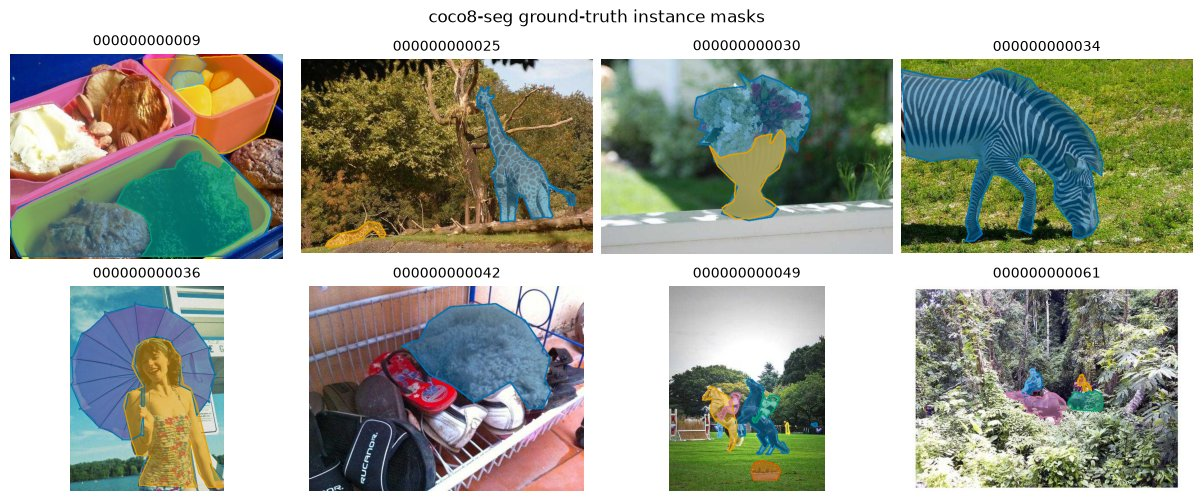

In [2]:
# --- Load coco8-seg: 8 COCO images with instance polygons rasterised to masks ---
# Each sample holds the RGB image (H x W x 3 uint8), an N x H x W boolean mask stack
# and the COCO class id of each instance.
NAMES = sk.coco_names()
samples = sk.load_coco_seg("coco8-seg")
for s in samples:
    classes = ", ".join(sorted({NAMES[c] for c in s.classes}))
    print(f"{s.name}: {s.image.shape[1]}x{s.image.shape[0]} px, {len(s.masks)} instances ({classes})")
fig = viz.show_images(
    [viz.overlay_masks(s.image, s.masks) for s in samples],
    titles=[s.name for s in samples],
    ncols=4,
    size=3.0,
    suptitle="coco8-seg ground-truth instance masks",
)
sk.show_jpeg(fig)  # photos: JPEG keeps the notebook small

## How SAM-style models work

All Segment Anything models share one decomposition:

1. **Image encoder** (heavy): a ViT turns the image (resized to 1008 px for SAM 3,
   1024 px for SAM 2.1) into a dense feature map. SAM 2.1 uses a hierarchical **Hiera**
   backbone; SAM 3 uses the **Perception Encoder** ViT that it shares with its text
   encoder and detector.
2. **Prompt encoder** (tiny): a click $(x, y)$ becomes a Fourier positional encoding plus a
   learned "positive" / "negative" embedding; a box becomes two corner tokens; a previous
   mask becomes a dense, convolved prompt.
3. **Mask decoder** (light): a two-way transformer lets prompt tokens and image features
   attend to each other and predicts low-resolution mask logits ($256 \times 256$ for
   SAM 2.1, $288 \times 288$ for SAM 3), which are upsampled to the image size, plus a
   **predicted IoU** for each mask.

The image encoder runs **once per image**; each new click only re-runs steps 2-3. That
split is what makes interactive annotation (and "click to grasp" robot interfaces)
responsive. We load both models in **bfloat16**: half the memory of fp32, and the
Blackwell GPU has native bf16 tensor cores.

In [3]:
# --- Load SAM 3 (tracker head) and SAM 2.1-Small in bfloat16 ---
# Sam3TrackerModel reads only the vision backbone + interactive head from the 3.4 GB
# facebook/sam3 checkpoint; Sam2Model loads facebook/sam2.1-hiera-small (184 MB).
models = {}
for mid in [sk.SAM3_ID, sk.SAM2_IDS["small"]]:
    torch.cuda.empty_cache()
    before = torch.cuda.memory_allocated()
    models[mid] = sk.PromptableSegmenter(mid, device=str(device))
    weights_mib = (torch.cuda.memory_allocated() - before) / 2**20
    print(f"{models[mid].label:10s} {models[mid].n_params_m:7.1f} M parameters | "
          f"weights on the GPU: {weights_mib:.0f} MiB (bf16)")

SAM 3        458.3 M parameters | weights on the GPU: 894 MiB (bf16)


SAM 2.1-S     38.5 M parameters | weights on the GPU: 81 MiB (bf16)


## One click, three answers: multimask output

A single positive click is **ambiguous**: a click on a person's dress may mean "the dress",
"the person" or "the person with her umbrella". Instead of guessing, the decoder outputs
**three masks** (roughly sub-part / part / whole) together with a predicted IoU
$\hat{s}_k$ for each, trained to regress the true IoU of that mask with the GT. At inference
you either keep $\arg\max_k \hat{s}_k$ or let the user pick.

We click at the **interior point** of the person mask: the pixel with the largest distance
to the mask border (peak of the distance transform). Unlike the centroid it is guaranteed
to lie on the object, even for non-convex shapes.

SAM 3: predicted IoU [0.039 0.379 0.891] | true IoU [0.017 0.859 0.319] -> keeps mask 2
SAM 2.1-S: predicted IoU [0.171 0.852 0.434] | true IoU [0.184 0.32  0.888] -> keeps mask 1


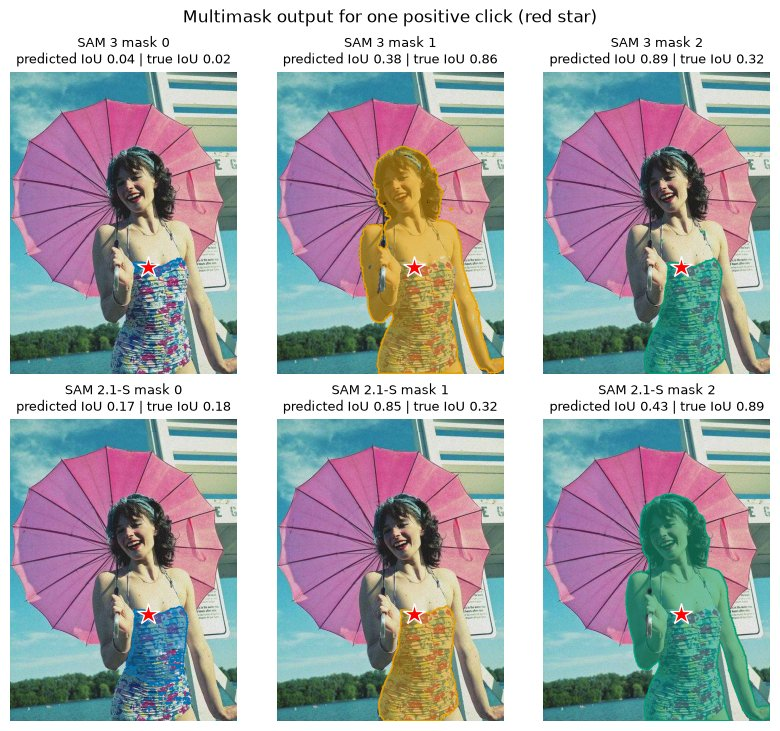

In [4]:
# --- One click, three masks: multimask output for an ambiguous click ---
# Click at the interior point of the person (sample 036); the decoder returns 3 masks,
# each with a predicted IoU. We also print the true IoU against the GT person mask.
s = samples[4]
gt = s.masks[list(s.classes).index(0)]  # class 0 = person
click = sk.interior_point(gt)  # (x, y) in pixels
fig, axes = plt.subplots(2, 3, figsize=(8.0, 7.2))
for row, seg in enumerate(models.values()):
    seg.set_image(s.image)
    masks, scores, _ = seg.predict([[click]], [[1]], multimask=True)  # 1 object x 3 masks
    for k in range(3):
        ax = axes[row, k]
        ax.imshow(viz.overlay_masks(s.image, masks[0, k][None], colors=[viz.color(k)]))
        ax.plot(*click, marker="*", color="red", ms=16, mec="white")
        iou = sk.j_measure(masks[0, k], gt)
        ax.set_title(f"{seg.label} mask {k}\npredicted IoU {scores[0, k]:.2f} | true IoU {iou:.2f}",
                     fontsize=9)
        ax.axis("off")
    true_iou = [sk.j_measure(m, gt) for m in masks[0]]
    print(f"{seg.label}: predicted IoU {np.round(scores[0], 3)} | true IoU {np.round(true_iou, 3)} "
          f"-> keeps mask {int(np.argmax(scores[0]))}")
fig.suptitle("Multimask output for one positive click (red star)")
viz.savefig(fig, PROJECT, "multimask_ambiguity")
sk.show_jpeg(fig)

## Box prompts

A box fixes the object's extent, so it removes most of the ambiguity and we ask for a
single mask per box (`multimask=False`). Boxes are also what an upstream detector
(YOLO, Grounding DINO) produces, which makes "detector box -> SAM mask" the most common
way to add masks to a detection pipeline (notebooks 02 and 04). All boxes of one image are
decoded in a single batched call, re-using the cached image embedding.

SAM 3: per-object IoU [0.343 0.55  0.931 0.686 0.848 0.851 0.875 0.865]
SAM 2.1-S: per-object IoU [0.34  0.557 0.94  0.722 0.858 0.839 0.865 0.867]


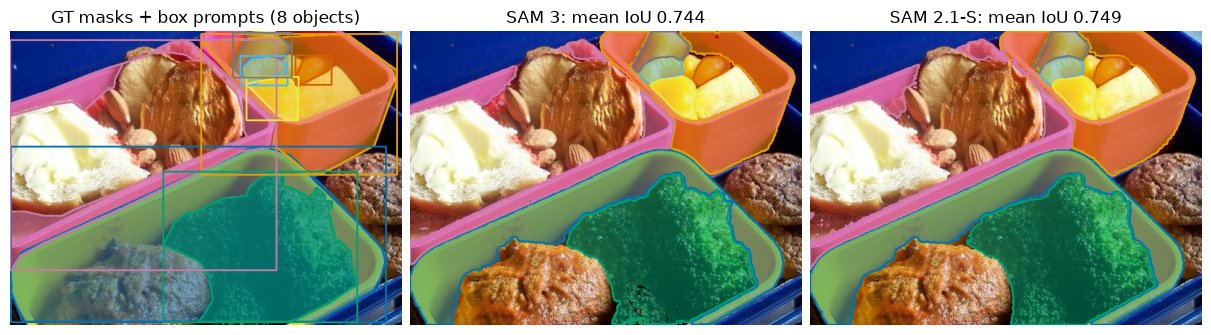

In [5]:
# --- Box prompts for every instance of one image (batched, single-mask output) ---
# Tight GT boxes [x1, y1, x2, y2] in pixels play the role of detector boxes.
s = samples[0]
boxes = [sk.mask_to_box(m) for m in s.masks]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].imshow(viz.draw_boxes(viz.overlay_masks(s.image, s.masks), np.array(boxes)))
axes[0].set_title(f"GT masks + box prompts ({len(boxes)} objects)")
for ax, seg in zip(axes[1:], models.values()):
    seg.set_image(s.image)
    masks, scores, _ = seg.predict(boxes=boxes, multimask=False)  # O x 1 x H x W
    ious = [sk.j_measure(m[0], g) for m, g in zip(masks, s.masks)]
    ax.imshow(viz.overlay_masks(s.image, masks[:, 0]))
    ax.set_title(f"{seg.label}: mean IoU {np.mean(ious):.3f}")
    print(f"{seg.label}: per-object IoU {np.round(ious, 3)}")
for ax in axes:
    ax.axis("off")
sk.show_jpeg(fig)

## Interactive refinement with positive and negative clicks

Interactive segmentation is evaluated with a **simulated annotator** (the protocol used by
the SAM papers and interactive-segmentation benchmarks):

1. click 1 is positive, at the object's interior point;
2. every next click goes to the centre (distance-transform peak) of the **largest error
   region** - a *positive* click in a missed region (false negative) or a *negative* click
   in a spurious region (false positive);
3. the previous low-resolution mask logits are fed back as a dense prompt, and only the
   first click uses multimask output.

Reported metrics are the **mean IoU after $k$ clicks** and **NoC@90**, the number of clicks
needed to reach IoU $\geq 0.9$ (capped; lower is better). Below, an object where one click
is not enough: the two elephants and three people of sample 061 are small and cluttered.

SAM 3: IoU after 1..4 clicks [0.54  0.729 0.779 0.821]
SAM 2.1-S: IoU after 1..4 clicks [0.611 0.676 0.758 0.787]


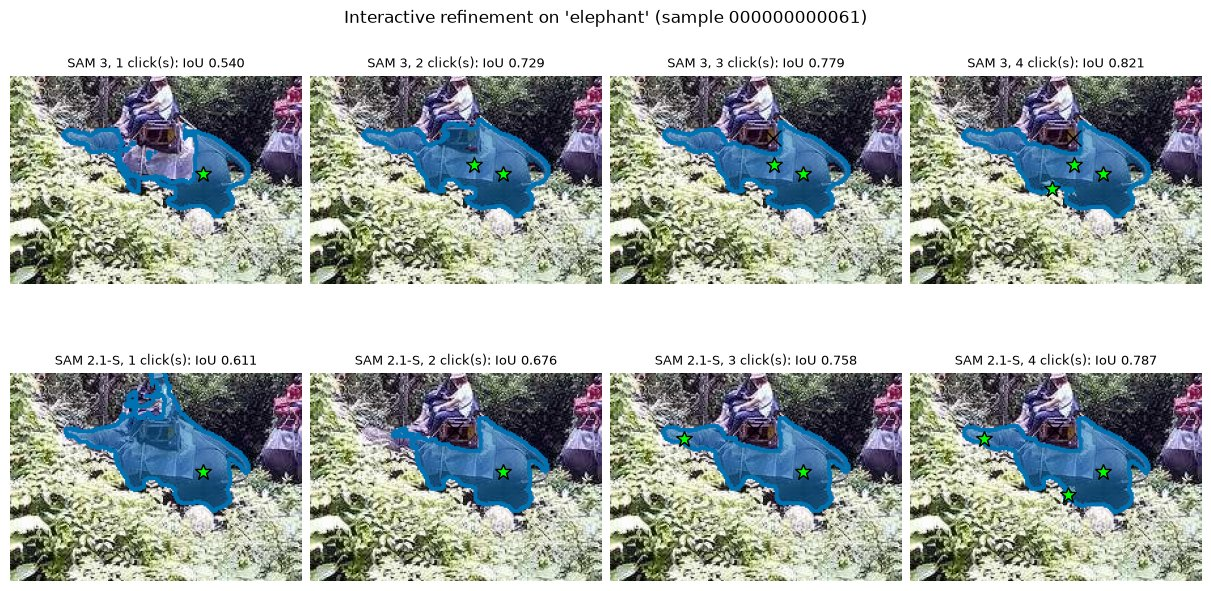

In [6]:
# --- Simulated interactive session on a hard, small object ---
# Green stars = positive clicks, red crosses = negative clicks; the title shows IoU vs GT.
s = samples[7]
obj = int(np.argmax([m.sum() for m in s.masks]))  # the larger elephant
gt = s.masks[obj]
x1, y1, x2, y2 = sk.mask_to_box(gt)
pad = 40  # zoom window around the object (pixels)
win = (slice(max(0, int(y1) - pad), int(y2) + pad), slice(max(0, int(x1) - pad), int(x2) + pad))
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for row, seg in enumerate(models.values()):
    seg.set_image(s.image)
    ious, steps = seg.interactive(gt, n_clicks=4, return_steps=True)
    for k, (mask, pts, labs) in enumerate(steps):
        ax = axes[row, k]
        ax.imshow(viz.overlay_masks(s.image, mask[None])[win])
        for (px, py), lab in zip(pts, labs):
            ax.plot(px - win[1].start, py - win[0].start, "*" if lab else "x", ms=12,
                    color="lime" if lab else "red", mec="black", mew=1.0)
        ax.set_title(f"{seg.label}, {k + 1} click(s): IoU {ious[k]:.3f}", fontsize=9)
        ax.axis("off")
    print(f"{seg.label}: IoU after 1..4 clicks {np.round(ious, 3)}")
fig.suptitle(f"Interactive refinement on '{NAMES[s.classes[obj]]}' (sample {s.name})")
viz.savefig(fig, PROJECT, "interactive_clicks")
sk.show_jpeg(fig)

## Latency and memory: encoder vs decoder

GPU kernels run asynchronously, so a timer around a PyTorch call measures only the kernel
*launch* unless we call `torch.cuda.synchronize()` before reading the clock.
`cvlab.bench.benchmark` does that, runs warm-up iterations (cuDNN autotuning, memory pool
growth) and reports the mean / percentiles over the timed iterations. We time:

* `set_image` - pre-processing + image encoder (once per image);
* `predict` - prompt encoder + mask decoder + upsampling the 3 masks to full resolution
  (once per click).

Peak VRAM (`torch.cuda.max_memory_allocated`) counts *everything* PyTorch has allocated,
so we first free the two models loaded above and then load the four sizes (SAM 3 and
SAM 2.1 tiny / small / base-plus) one at a time: each peak is that model's weights plus
the activations of this workload.

In [7]:
# --- Benchmark encoder and decoder latency + peak VRAM for 4 model sizes ---
# One 640x480 image (sample 009), one positive click; 20 encoder / 50 decoder iterations.
# Each model is loaded alone inside track_vram, so its peak excludes the other models.
import gc

del models, seg  # `seg` still points at the last model of the loops above
gc.collect()
s = samples[0]
click = sk.interior_point(s.masks[0])
speed_rows = []
for mid in [sk.SAM3_ID, *sk.SAM2_IDS.values()]:
    torch.cuda.empty_cache()
    with track_vram() as mem:
        seg = sk.PromptableSegmenter(mid, device=str(device))
        enc = benchmark(seg.set_image, s.image, warmup=3, iters=20)
        dec = benchmark(seg.predict, [[click]], [[1]], warmup=5, iters=50)
    speed_rows.append({
        "model": seg.label,
        "params (M)": round(seg.n_params_m, 1),
        "encoder ms": round(enc["mean_ms"], 1),
        "decoder ms": round(dec["mean_ms"], 2),
        "clicks/s after encoding": round(dec["fps"], 0),
        "peak VRAM (MiB)": round(mem.peak_mb, 0),
    })
    del seg
    gc.collect()
speed = pd.DataFrame(speed_rows).set_index("model")
speed

,params (M),encoder ms,decoder ms,clicks/s after encoding,peak VRAM (MiB)
model,,,,,
SAM 3,458.3,343.4,3.26,306.0,1163.0
SAM 2.1-T,31.4,33.4,3.92,255.0,331.0
SAM 2.1-S,38.5,39.7,3.28,305.0,346.0
SAM 2.1-B+,73.3,65.7,3.21,312.0,440.0


## Results

The cells above are single examples. For a real comparison,
`benchmark_coco.py --task prompts` ran every model on **coco128-seg** (128 COCO images,
861 instances with area $\geq 100$ px) with three prompt types per instance:

* **1 click (top)** - one interior click, keep the mask with the highest predicted IoU;
* **1 click (best of 3)** - the same click, but an oracle picks the best of the 3 masks
  (upper bound of what a user choosing among the masks would get);
* **box** - the tight GT box;
* **k clicks** - the simulated interactive session (up to 5 clicks).

Caveat: COCO train2017 images were part of the training data of many models, and
polygon annotations are coarse, so IoU saturates around 0.8-0.9 even for good masks.
Treat the numbers as a *relative* comparison under identical prompts.

In [8]:
# --- Load the coco128-seg benchmark results (benchmark_coco.py --task prompts) ---
# JSON: per-model summary; CSV: one row per (model, instance) with IoU per prompt type.
from cvlab.io import load_json

bench = load_json(RESULTS / "prompts_coco128-seg.json")
inst = pd.read_csv(RESULTS / "prompts_coco128-seg_instances.csv")
order = [m for m in ["SAM 2.1-T", "SAM 2.1-S", "SAM 2.1-B+", "SAM 3"] if m in bench["models"]]
print(f"{bench['meta']['n_images']} images, {bench['models'][order[0]]['n_instances']} instances "
      f"(area >= {bench['meta']['min_area_px']} px)")
print(inst.groupby("model")["size"].value_counts().unstack()[["small", "medium", "large"]])

128 images, 861 instances (area >= 100 px)
size        small  medium  large
model                           
SAM 2.1-B+    337     296    228
SAM 2.1-S     337     296    228
SAM 2.1-T     337     296    228
SAM 3         337     296    228


Mean IoU per prompt type and model, and the IoU-vs-clicks curve of the interactive
protocol:

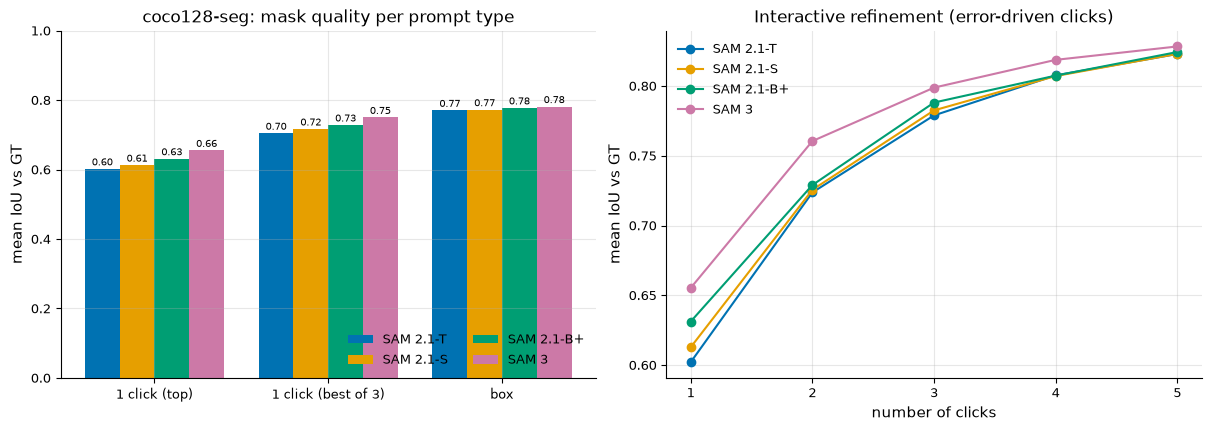

In [9]:
# --- Figure: mIoU per prompt type, and mIoU vs number of clicks ---
# Left: grouped bars (one group per prompt type). Right: interactive curve, 1..5 clicks.
prompt_cols = {"1 click (top)": "mIoU_click_top", "1 click (best of 3)": "mIoU_click_oracle",
               "box": "mIoU_box"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
width = 0.8 / len(order)
for i, m in enumerate(order):
    vals = [bench["models"][m][c] for c in prompt_cols.values()]
    xs = np.arange(len(prompt_cols)) + (i - (len(order) - 1) / 2) * width
    ax1.bar(xs, vals, width, label=m, color=viz.color(i, unit=True))
    for x, v in zip(xs, vals):
        ax1.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
    curve = bench["models"][m]["mIoU_per_click"]
    ax2.plot(range(1, len(curve) + 1), curve, "o-", label=m, color=viz.color(i, unit=True))
ax1.set_xticks(range(len(prompt_cols)), list(prompt_cols))
ax1.set_ylim(0, 1)
ax1.set_ylabel("mean IoU vs GT")
ax1.set_title("coco128-seg: mask quality per prompt type")
ax1.legend(ncols=2, loc="lower right")
ax2.set_xlabel("number of clicks")
ax2.set_ylabel("mean IoU vs GT")
ax2.set_title("Interactive refinement (error-driven clicks)")
ax2.set_xticks(range(1, bench["meta"]["n_clicks"] + 1))
ax2.legend()
viz.savefig(fig, PROJECT, "prompt_benchmark")
plt.show()

Object size matters: COCO calls an instance *small* below $32^2$ px, *large* above
$96^2$ px. A click on a small object leaves the model more room to segment the wrong
thing, and polygon annotation error is a larger fraction of a small mask.

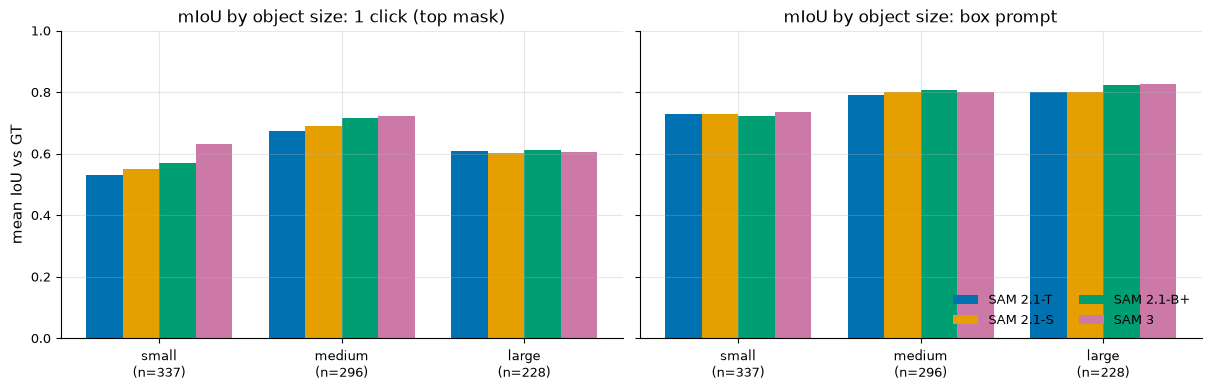

In [10]:
# --- Figure: 1-click and box mIoU by COCO object-size bucket ---
# Bars per model inside each size bucket; the number of instances is in the x labels.
sizes = ["small", "medium", "large"]
counts = inst[inst.model == order[0]]["size"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, title in zip(axes, ["click_top", "box"], ["1 click (top mask)", "box prompt"]):
    tab = inst.pivot_table(index="size", columns="model", values=col, aggfunc="mean").loc[sizes]
    for i, m in enumerate(order):
        xs = np.arange(len(sizes)) + (i - (len(order) - 1) / 2) * width
        ax.bar(xs, tab[m], width, label=m, color=viz.color(i, unit=True))
    ax.set_xticks(range(len(sizes)), [f"{z}\n(n={counts[z]})" for z in sizes])
    ax.set_title(f"mIoU by object size: {title}")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("mean IoU vs GT")
axes[1].legend(ncols=2, loc="lower right")
viz.savefig(fig, PROJECT, "prompt_by_size")
plt.show()

Summary table: the benchmark metrics (coco128-seg) next to the latency and memory measured
above (one 640x480 image, bf16). NoC@85 / NoC@90 = mean number of clicks to reach IoU
0.85 / 0.90, where an instance that never gets there within 5 clicks counts as 6.

In [11]:
# --- Summary table: accuracy (coco128-seg benchmark) + speed/memory (this notebook) ---
cols = {"mIoU_click_top": "mIoU 1 click", "mIoU_click_oracle": "mIoU 1 click best-of-3",
        "mIoU_box": "mIoU box", "NoC@85": "NoC@85", "NoC@90": "NoC@90",
        "peak_vram_MiB": "benchmark peak VRAM (MiB)"}
acc = pd.DataFrame({m: {v: bench["models"][m][k] for k, v in cols.items()} for m in order}).T
acc["mIoU 5 clicks"] = [bench["models"][m]["mIoU_per_click"][-1] for m in order]
summary = speed.join(acc).loc[order]
summary.to_csv(RESULTS / "nb01_summary.csv")
summary

,params (M),encoder ms,decoder ms,clicks/s after encoding,peak VRAM (MiB),mIoU 1 click,mIoU 1 click best-of-3,mIoU box,NoC@85,NoC@90,benchmark peak VRAM (MiB),mIoU 5 clicks
model,,,,,,,,,,,,
SAM 2.1-T,31.4,33.4,3.92,255.0,331.0,0.6021,0.7047,0.7705,3.99,4.93,328.0,0.8229
SAM 2.1-S,38.5,39.7,3.28,305.0,346.0,0.6128,0.7169,0.7725,3.91,4.86,344.0,0.8230
SAM 2.1-B+,73.3,65.7,3.21,312.0,440.0,0.6312,0.7284,0.7776,3.82,4.82,438.0,0.8243
SAM 3,458.3,343.4,3.26,306.0,1163.0,0.6553,0.7502,0.7815,3.84,4.90,1128.0,0.8283


### Takeaways

* **A box is the strongest single prompt, and it makes the model choice almost irrelevant.**
  Box mIoU on coco128-seg spans only 0.7705 (SAM 2.1-T) to 0.7815 (SAM 3). If an upstream
  detector already supplies boxes, SAM 2.1-T/S produce nearly the same masks as SAM 3 for
  about a tenth of its encoder time.
* **One click is ambiguous, and the predicted IoU often picks the wrong level.** The
  top-scored mask reaches 0.6021-0.6553 mIoU, the best of the three masks 0.7047-0.7502, so
  about 0.1 IoU is lost to the selection step alone. In the umbrella example both models
  keep the "swimsuit" mask (true IoU 0.32) although a "person" mask is among their three
  candidates (true IoU 0.86 for SAM 3, 0.89 for SAM 2.1-S). Showing the three candidates to
  the operator, or asking for a second click, recovers most of that loss.
* **SAM 3 helps most where a click carries the least information.** Its 1-click mIoU
  (0.6553) is the best of the four models and the size figure shows the largest gap on
  small objects. With a box, or after 5 simulated clicks (0.8229-0.8283 for all four
  models), the gap almost closes.
* **The COCO polygons cap the attainable IoU.** NoC@90 is 4.82-4.93 for every model: most
  instances never reach IoU 0.9 within 5 clicks (they count as 6). Polygon outlines are
  coarse, so part of the remaining "error" is annotation noise; notebook 03 measures
  boundary quality on the finer DAVIS masks instead.
* **The cost is in the encoder.** SAM 3 encodes an image in 343.4 ms versus 33.4-65.7 ms
  for SAM 2.1 (458.3 M vs 31.4-73.3 M parameters; peak VRAM 1163 vs 331-440 MiB). The
  decoder costs 3.21-3.92 ms for every model, so once an image is encoded all four answer
  more than 250 clicks/s. Interactive use feels instant with any of them; only the time to
  the first mask differs.

## Exercises

Solutions: `projects/05_segmentation/solutions/` (run them from the repository root).

**Exercise 1 - "segment everything".** Without any prompt, SAM can tile the image with a
grid of clicks and keep the confident, non-duplicate masks (automatic mask generation).
Use the `transformers` `pipeline("mask-generation", model=sk.SAM2_IDS["small"])` on
sample 009, count the masks and plot them over the image. How many of the 8 GT objects
are covered by a generated mask with IoU > 0.5?

In [12]:
# --- Exercise 1: automatic mask generation ("segment everything") ---
# TODO: build pipeline("mask-generation", model=sk.SAM2_IDS["small"], device=0,
#       dtype=torch.bfloat16), run it on samples[0].image with points_per_batch=64,
#       overlay the masks and match them to samples[0].masks with sk.mask_iou_matrix.

**Exercise 2 - boundary quality.** IoU is dominated by the object's interior; a mask can
reach IoU 0.9 with a ragged outline. Compute the DAVIS boundary F-measure
(`sk.f_measure`) of the click and box masks of SAM 3 and SAM 2.1-S on all coco8-seg
instances. Which prompt gives sharper boundaries?

In [13]:
# --- Exercise 2: boundary F-measure of click vs box masks ---
# TODO: for each model in `models` and each instance of `samples`, predict a mask from
#       one interior click (top mask) and from the GT box, then average sk.f_measure.

**Exercise 3 - when does the predicted IoU pick the wrong mask?** Using the benchmark CSV
(`inst`), compute per model and per size bucket how often the top-scored mask is *not*
the best of the three (`click_top < click_oracle`) and the mean IoU lost when that
happens.

In [14]:
# --- Exercise 3: how often does the predicted IoU choose the wrong mask? ---
# TODO: add a boolean column inst["wrong_pick"] = inst.click_top < inst.click_oracle - 1e-6,
#       then group by ["model", "size"] and aggregate the rate and the mean IoU gap.